In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
#Raúl
import pandas as pd # Estructura y manipulación de datos
url='/content/drive/MyDrive/Machine Learning/Prueba 2/Anexo ET_demo_round_traces_2022.csv'
df = pd.read_csv(url, sep=";", encoding='utf-8')


/tmp/ipython-input-2-705487826.py:4: DtypeWarning: Columns (6,7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(url, sep=";", encoding='utf-8')


In [ ]:
#Sofia
url = '/content/drive/MyDrive/Fundamentos de machine learning/Anexo ET_demo_round_traces_2022.csv'
df = pd.read_csv(url, sep=";", encoding='utf-8')


In [3]:
#Con esta linea de codigo podemos asegurarnos de que las variables a utilizar sean numericas
df['MatchAssists'] = pd.to_numeric(df['MatchAssists'], errors='coerce')
df['TimeAlive'] = pd.to_numeric(df['TimeAlive'], errors='coerce')
df['MatchHeadshots'] = pd.to_numeric(df['MatchHeadshots'], errors='coerce')
df['RoundKills'] = pd.to_numeric(df['RoundKills'], errors='coerce')

In [4]:
# 3.1. Imputar NaN en columnas numéricas usando la media
import numpy as np # Programación vectorial
num_cols = df.select_dtypes(include=[np.number]).columns

for col in num_cols:
    if df[col].isnull().sum() > 0:
        mean_value = df[col].mean()
        df[col].fillna(mean_value, inplace=True)

/tmp/ipython-input-4-1837726787.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(mean_value, inplace=True)


In [5]:
# 3.2.En columnas categóricas rellenamos con el valor más frecuente
cat_cols = df.select_dtypes(include=['object']).columns

for col in cat_cols:
    if df[col].isnull().sum() > 0:
        mode_value = df[col].mode()[0]
        df[col].fillna(mode_value, inplace=True)

/tmp/ipython-input-5-3727136605.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(mode_value, inplace=True)
/tmp/ipython-input-5-3727136605.py:7: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col].fillna(mode_value, inplace=True)


In [6]:
print("\nValores nulos por columna luego de añadir el valor segun la media:")
print(df.isnull().sum())


Valores nulos por columna luego de añadir el valor segun la media:
Unnamed: 0                     0
Map                            0
Team                           0
InternalTeamId                 0
MatchId                        0
RoundId                        0
RoundWinner                    0
MatchWinner                    0
Survived                       0
AbnormalMatch                  0
TimeAlive                      0
TravelledDistance              0
RLethalGrenadesThrown          0
RNonLethalGrenadesThrown       0
PrimaryAssaultRifle            0
PrimarySniperRifle             0
PrimaryHeavy                   0
PrimarySMG                     0
PrimaryPistol                  0
FirstKillTime                  0
RoundKills                     0
RoundAssists                   0
RoundHeadshots                 0
RoundFlankKills                0
RoundStartingEquipmentValue    0
TeamStartingEquipmentValue     0
MatchKills                     0
MatchFlankKills                0
MatchAss

In [7]:
import pandas as pd
from imblearn.over_sampling import SMOTE

# 1. Limpieza y filtrado de Survived y AbnormalMatch
df['Survived'] = df['Survived'].astype(str).str.strip()
df = df[df['Survived'].isin(['True', 'False'])].copy()
df['Survived'] = df['Survived'].map({'True': 1, 'False': 0})
df = df[df['AbnormalMatch'] == False]


# 6. Selección de variables para modelo
X = df[['RLethalGrenadesThrown', 'RNonLethalGrenadesThrown','RoundKills',]].copy()
y = df['Survived']

# 7. Verificar nulos y shapes
print("Valores únicos en y:", y.unique())
print("¿Hay nulos en y?", y.isna().any())
print("¿Hay nulos en X?", X.isna().any().any())
print("Shape de X:", X.shape)
print("Shape de y:", y.shape)

# 8. Aplicar SMOTE
sm = SMOTE(random_state=42)
X_res, y_res = sm.fit_resample(X, y)

print("Distribución después de SMOTE:")
print(y_res.value_counts())


Valores únicos en y: [0 1]
¿Hay nulos en y? False
¿Hay nulos en X? False
Shape de X: (79157, 3)
Shape de y: (79157,)
Distribución después de SMOTE:
Survived
0    47214
1    47214
Name: count, dtype: int64


In [8]:
from sklearn.model_selection import train_test_split

# Dividir los datos balanceados en train y test
X_train, X_test, y_train, y_test = train_test_split(X_res, y_res, test_size=0.2, random_state=42)

# Entrenar el modelo
from sklearn.ensemble import RandomForestClassifier

modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42)
modelo_rf.fit(X_train, y_train)

# Predecir en test
y_pred_rf = modelo_rf.predict(X_test)

# Evaluar
from sklearn.metrics import classification_report, confusion_matrix

print("Reporte de clasificación Random Forest:")
print(classification_report(y_test, y_pred_rf))



Reporte de clasificación Random Forest:
              precision    recall  f1-score   support

           0       0.64      0.71      0.68      9487
           1       0.67      0.60      0.63      9399

    accuracy                           0.66     18886
   macro avg       0.66      0.66      0.65     18886
weighted avg       0.66      0.66      0.65     18886



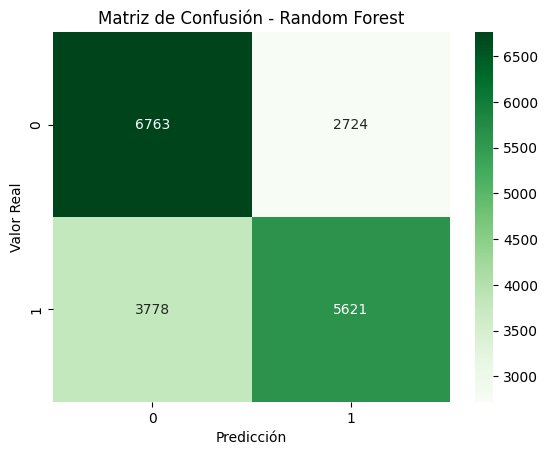

              precision    recall  f1-score   support

           0       0.64      0.71      0.68      9487
           1       0.67      0.60      0.63      9399

    accuracy                           0.66     18886
   macro avg       0.66      0.66      0.65     18886
weighted avg       0.66      0.66      0.65     18886



In [9]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Matriz de confusión
matriz_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(matriz_rf, annot=True, fmt='d', cmap='Greens')
plt.title("Matriz de Confusión - Random Forest")
plt.xlabel("Predicción")
plt.ylabel("Valor Real")
plt.show()

# Métricas
print(classification_report(y_test, y_pred_rf))

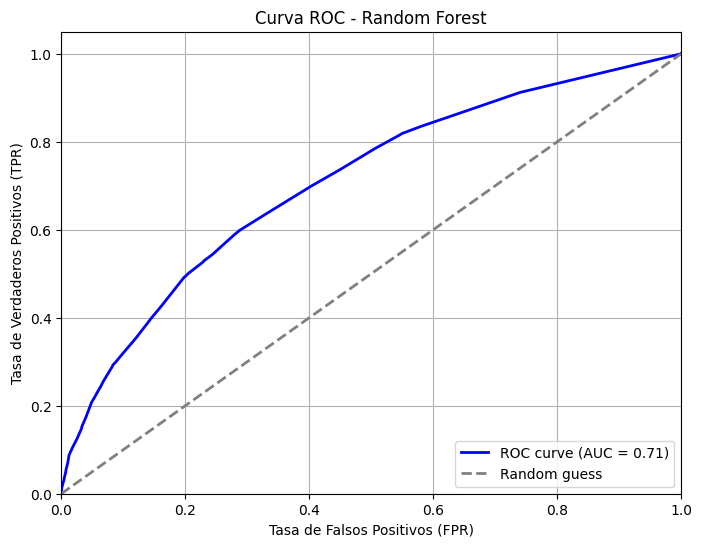

In [10]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Obtener probabilidades de clase positiva
y_proba_rf = modelo_rf.predict_proba(X_test)[:, 1]

# Calcular curva ROC
fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, y_proba_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)

# Graficar curva ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr_rf, tpr_rf, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc_rf:.2f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Random guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Curva ROC - Random Forest')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [16]:
import joblib

# Guardar tus datos de test

joblib.dump(y_test, 'y_test.pkl')


['y_test.pkl']

In [15]:
joblib.dump(X_test, 'X_test.pkl')

['X_test.pkl']

In [12]:
import joblib

# Guardar el modelo entrenado
joblib.dump(modelo_rf, 'modelo_rf.pkl')

from google.colab import files

# Descargar archivo .pkl a tu PC
files.download('modelo_rf.pkl')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Precision: de todas las veces que el modelo predijo victoria (1), acertó el 61%. Y cuando predijo derrota (0), acertó el 58%.

Recall: de todas las veces que el resultado real fue victoria, el modelo identificó correctamente el 63% de ellas. Para las derrotas, acertó el 56%.

F1-score: combina precisión y recall en una sola métrica. En general, el modelo tiene un F1 moderado (~60%) para ambas clases, lo que indica que está razonablemente equilibrado.

Accuracy general: el modelo acierta en el 60% de los casos.

